# 01 · Datos y análisis exploratorio
**Proyecto final — Redes Neuronales y Aprendizaje Profundo (EAFIT)**
*Clasificación de enfermedades foliares del café y evaluación de la generalización ante cambio de dominio*

Este notebook:
1. Descarga los datasets (BRACOL para entrenar, RoCoLe como conjunto **externo**).
2. Construye las tablas de etiquetas y la partición **train / val / test** estratificada (sin fuga de información).
3. Analiza distribución de clases, ejemplos visuales y propiedades de las imágenes.
4. **Cuantifica el cambio de dominio** BRACOL → RoCoLe y prepara versiones recortadas / con fondo enmascarado de RoCoLe para los experimentos de generalización.

Todas las figuras se guardan en `figures/` para usarlas en las diapositivas e informe.

| Dataset | Rol | Origen | Licencia |
|---|---|---|---|
| **BRACOL** (Krohling, Esgario & Ventura, 2019) | Entrenamiento / validación / prueba | Café **arábica**, Espírito Santo (Brasil). Hoja desprendida sobre fondo blanco | CC BY 4.0 — doi:10.17632/yy2k5y8mxg.1 |
| **RoCoLe** (Parraga-Alava et al., 2019) | Evaluación externa | Café **robusta**, Ecuador. Hoja en la planta, en campo | CC BY 4.0 — doi:10.17632/c5yvn32dzg.2 |

In [1]:
import os, sys, io, json, csv, zipfile, random, shutil
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageDraw, ImageOps
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # En Colab se trabaja sobre Google Drive para no re-descargar en cada sesión
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/ProyectoCafe")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
for p in (RAW / "bracol", RAW / "rocole" / "images", PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
print("ROOT =", ROOT)

ROOT = C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final


## 1. Descarga de datos

**Nota de reproducibilidad:** el `.zip` de BRACOL publicado en Mendeley está **truncado** (164 MB, sin directorio central:
solo se recuperan ~1400 de 1747 hojas y falta la carpeta de síntomas). Por eso se descarga la copia completa enlazada por los
autores en su repositorio oficial ([esgario/lara2018](https://github.com/esgario/lara2018)).
Las imágenes de RoCoLe se descargan usando las URLs del archivo de anotaciones oficial (`RoCoLE-csv.csv`, Mendeley).

In [2]:
BRACOL_GDRIVE_ID = "15YHebAGrx1Vhv8-naave-R5o3Uo70jsm"   # enlace oficial en el README de esgario/lara2018
ROCOLE_CSV_URL = ("https://data.mendeley.com/public-files/datasets/c5yvn32dzg/files/"
                  "e39cecdd-8dca-445a-b734-10229427f2fa/file_downloaded")

def download(url, dst, chunk=1 << 20):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 0:
        return dst
    tmp = dst.with_suffix(dst.suffix + ".part")
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f:
            for b in r.iter_content(chunk):
                f.write(b)
    tmp.rename(dst)
    return dst

# --- BRACOL ---
bracol_zip = RAW / "bracol" / "bracol_gdrive.zip"
download(f"https://drive.usercontent.google.com/download?id={BRACOL_GDRIVE_ID}&export=download&confirm=t", bracol_zip)
BRACOL = RAW / "bracol" / "coffee-datasets"
if not (BRACOL / "leaf" / "dataset.csv").exists():
    with zipfile.ZipFile(bracol_zip) as z:
        z.extractall(RAW / "bracol")
print("BRACOL hojas:", len(list((BRACOL / "leaf" / "images").glob("*.jpg"))))

# --- RoCoLe ---
rocole_csv = download(ROCOLE_CSV_URL, RAW / "rocole" / "RoCoLE-csv.csv")
csv.field_size_limit(10**9)
rocole_rows = list(csv.DictReader(open(rocole_csv, encoding="utf8")))

def fetch_rocole(row):
    name = row["External ID"].strip()            # algunos IDs traen espacios al final
    return download(row["Labeled Data"], RAW / "rocole" / "images" / name)

with ThreadPoolExecutor(16) as ex:
    list(ex.map(fetch_rocole, rocole_rows))
print("RoCoLe imágenes:", len(list((RAW / "rocole" / "images").glob("*.jpg"))))

BRACOL hojas: 1747


RoCoLe imágenes: 1560


## 2. BRACOL — etiquetas y distribución de clases

Cada hoja tiene una etiqueta de **estrés predominante** (0 sana, 1 minador, 2 roya, 3 phoma, 4 cercospora, 5 indeterminado),
indicadores binarios por enfermedad (una hoja puede tener varias) y un nivel de **severidad** (0–4).
La tarea principal es **clasificación multiclase de 5 clases** con el estrés predominante; se descartan las 62 hojas
*indeterminadas* porque no tienen una clase objetivo definida.

In [3]:
CLASSES = ["sana", "minador", "roya", "phoma", "cercospora"]
CLASSES_EN = ["healthy", "miner", "rust", "phoma", "cercospora"]

bra = pd.read_csv(BRACOL / "leaf" / "dataset.csv")
bra["path"] = bra["id"].map(lambda i: str((BRACOL / "leaf" / "images" / f"{i}.jpg").relative_to(ROOT)).replace("\\", "/"))
print("Total hojas:", len(bra))
print("Indeterminadas (descartadas):", (bra.predominant_stress == 5).sum())
bra = bra[bra.predominant_stress < 5].reset_index(drop=True)
bra["label"] = bra["predominant_stress"].astype(int)
bra["clase"] = bra["label"].map(dict(enumerate(CLASSES)))
bra["n_estreses"] = bra[["miner", "rust", "phoma", "cercospora"]].sum(axis=1)

counts = bra["clase"].value_counts().reindex(CLASSES)
display(pd.DataFrame({"n": counts, "%": (100 * counts / counts.sum()).round(1)}))
print(f"Desbalance máx/mín: {counts.max() / counts.min():.1f}x")

Total hojas: 1747
Indeterminadas (descartadas): 62


,n,%
clase,,
sana,272,16.1
minador,387,23.0
roya,531,31.5
phoma,348,20.7
cercospora,147,8.7


Desbalance máx/mín: 3.6x


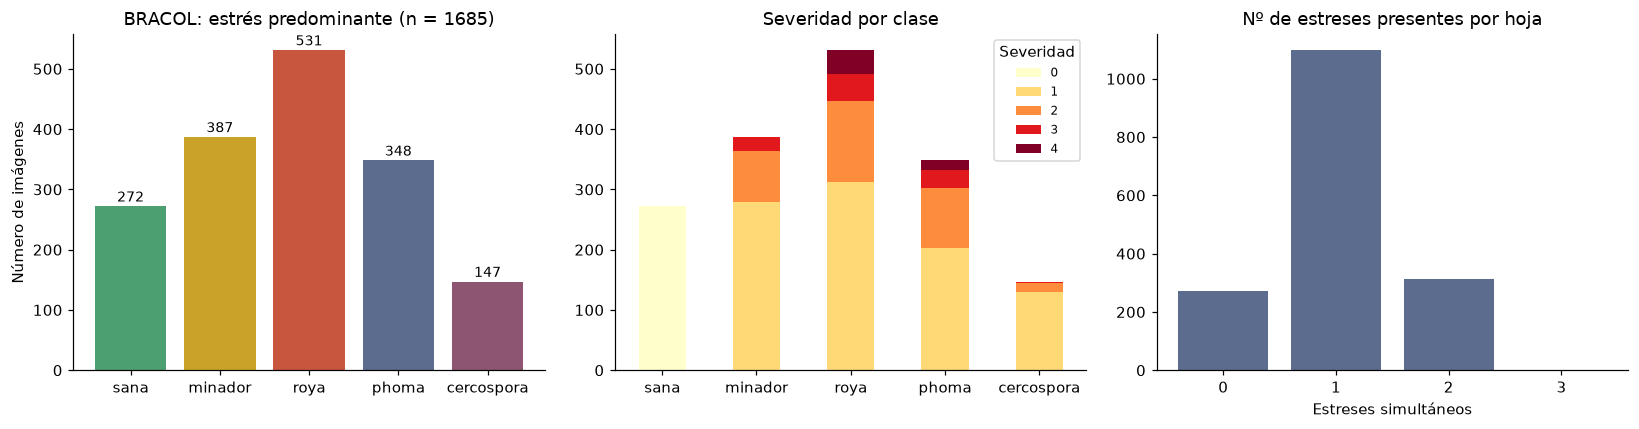

Hojas enfermas con >1 estrés: 315 (18.7 %) → la etiqueta 'predominante' simplifica un problema multi-etiqueta


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = ["#4C9F70", "#C9A227", "#C8553D", "#5B6C8F", "#8E5572"]

ax = axes[0]
ax.bar(CLASSES, counts.values, color=colors)
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, str(v), ha="center", fontsize=9)
ax.set_title("BRACOL: estrés predominante (n = %d)" % counts.sum()); ax.set_ylabel("Número de imágenes")

ax = axes[1]
sev = pd.crosstab(bra["clase"], bra["severity"]).reindex(CLASSES)
sev.plot(kind="bar", stacked=True, ax=ax, colormap="YlOrRd", rot=0)
ax.set_title("Severidad por clase"); ax.set_xlabel(""); ax.legend(title="Severidad", fontsize=8)

ax = axes[2]
multi = bra["n_estreses"].value_counts().sort_index()
ax.bar(multi.index.astype(str), multi.values, color="#5B6C8F")
ax.set_title("Nº de estreses presentes por hoja"); ax.set_xlabel("Estreses simultáneos")
plt.tight_layout(); plt.savefig(FIG / "01_bracol_distribucion.png"); plt.show()

print("Hojas enfermas con >1 estrés:", (bra.n_estreses > 1).sum(),
      f"({100 * (bra.n_estreses > 1).mean():.1f} %) → la etiqueta 'predominante' simplifica un problema multi-etiqueta")

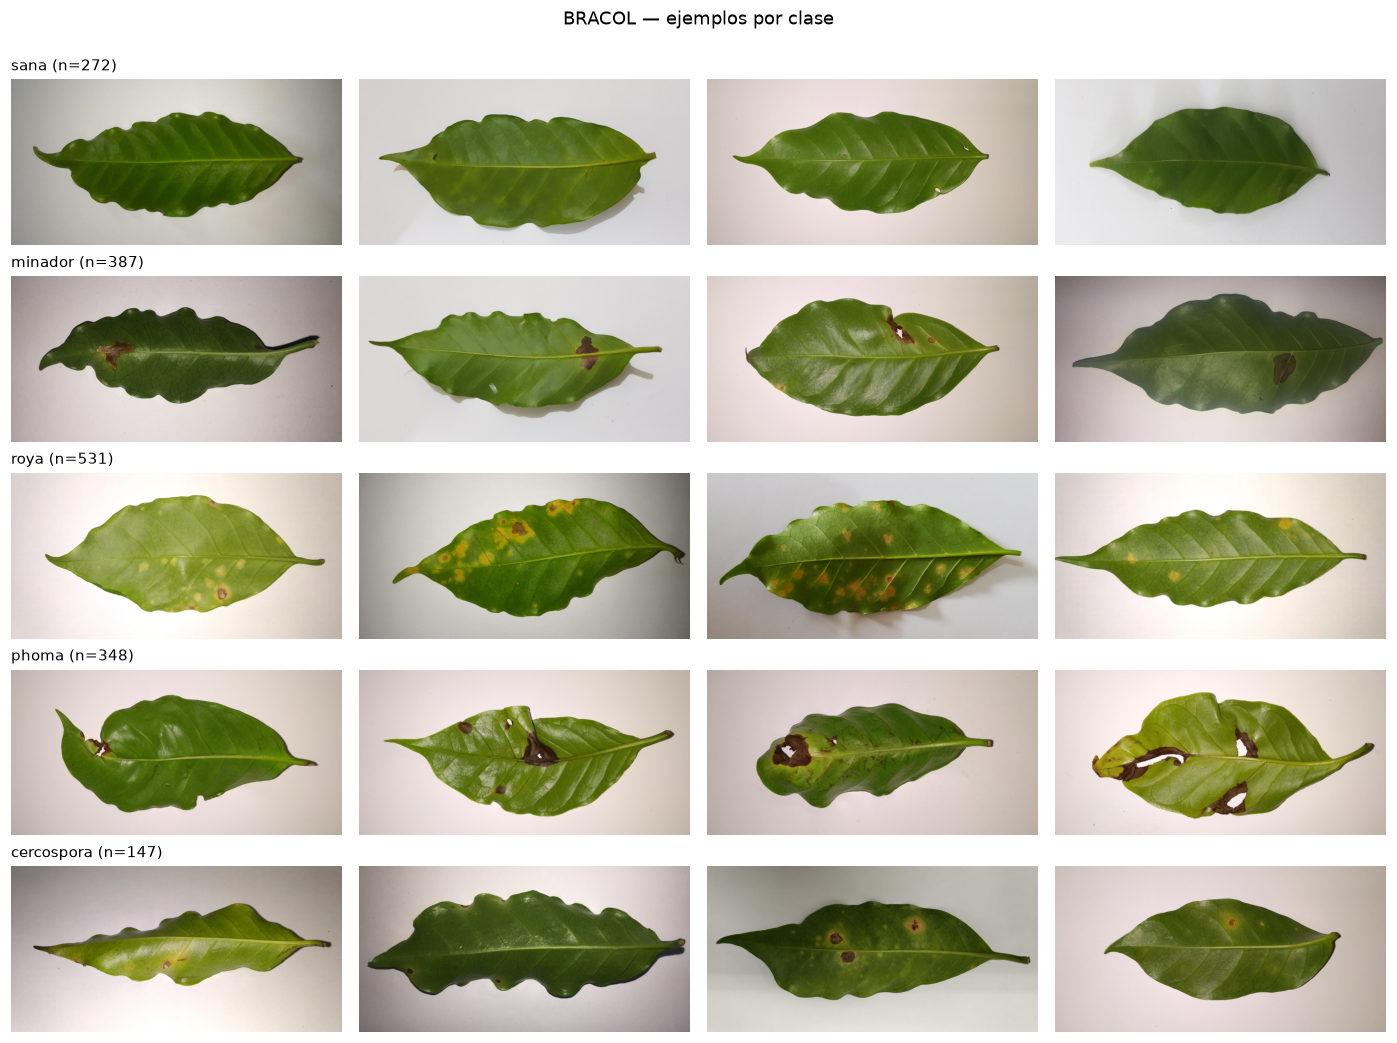

In [5]:
def show_grid(df, by, classes, n=4, title=None, fname=None, loader=None):
    loader = loader or (lambda p: Image.open(ROOT / p).convert("RGB"))
    fig, axes = plt.subplots(len(classes), n, figsize=(n * 3.2, len(classes) * 1.9))
    for r, c in enumerate(classes):
        sub = df[df[by] == c]
        sample = sub.sample(min(n, len(sub)), random_state=SEED)
        for k in range(n):
            ax = axes[r, k]; ax.axis("off")
            if k < len(sample):
                ax.imshow(loader(sample.iloc[k]["path"]))
            if k == 0:
                ax.set_title(f"{c} (n={len(sub)})", loc="left", fontsize=10)
    if title: fig.suptitle(title, y=1.0)
    plt.tight_layout()
    if fname: plt.savefig(FIG / fname)
    plt.show()

show_grid(bra, "clase", CLASSES, title="BRACOL — ejemplos por clase", fname="01_bracol_ejemplos.png")

## 3. Partición train / val / test (sin fuga de información)

- **70 / 15 / 15 estratificado** por clase, semilla fija (42) → misma proporción de clases en los tres conjuntos.
- En BRACOL cada imagen es una **hoja física distinta** (una foto por hoja), así que dividir por imagen no filtra información.
- Las estadísticas de normalización se toman de ImageNet (modelos preentrenados), **no** se calculan sobre val/test.
- El *data augmentation* se aplicará **solo** en entrenamiento (notebook 02).
- RoCoLe **nunca** se usa para entrenar ni para escoger hiperparámetros: es exclusivamente el conjunto externo.

In [6]:
train_df, tmp = train_test_split(bra, test_size=0.30, stratify=bra["label"], random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp["label"], random_state=SEED)
bra["split"] = "train"
bra.loc[val_df.index, "split"] = "val"
bra.loc[test_df.index, "split"] = "test"

tab = pd.crosstab(bra["clase"], bra["split"]).reindex(CLASSES)[["train", "val", "test"]]
tab.loc["TOTAL"] = tab.sum()
display(tab)

# pesos de clase (inverso de la frecuencia en train) para la función de pérdida
freq = bra[bra.split == "train"]["label"].value_counts().sort_index()
class_weights = (freq.sum() / (len(freq) * freq)).round(3)   # w_c = N / (K · n_c)
print("Pesos de clase (train):", dict(zip(CLASSES, class_weights.tolist())))

cols = ["id", "path", "label", "clase", "miner", "rust", "phoma", "cercospora", "severity", "split"]
bra[cols].to_csv(PROC / "bracol_leaf.csv", index=False)
json.dump({"classes": CLASSES, "classes_en": CLASSES_EN, "class_weights": class_weights.tolist(), "seed": SEED},
          open(PROC / "meta.json", "w"), indent=2, ensure_ascii=False)
print("Guardado:", PROC / "bracol_leaf.csv")

split,train,val,test
clase,,,
sana,190,41,41
minador,271,58,58
roya,372,79,80
phoma,243,53,52
cercospora,103,22,22
TOTAL,1179,253,253


Pesos de clase (train): {'sana': 1.241, 'minador': 0.87, 'roya': 0.634, 'phoma': 0.97, 'cercospora': 2.289}
Guardado: C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\data\processed\bracol_leaf.csv


## 4. RoCoLe — conjunto externo

RoCoLe tiene 6 clases: `healthy`, `red_spider_mite`, `rust_level_1..4`.
**Mapeo al espacio de etiquetas de BRACOL:**

| RoCoLe | → BRACOL | Uso |
|---|---|---|
| healthy | sana | evaluación externa |
| rust_level_1–4 | roya | evaluación externa (y análisis por severidad) |
| red_spider_mite | — (no existe en BRACOL) | análisis *fuera de distribución*: ¿qué predice el modelo ante una plaga que nunca vio? |

Minador, phoma y cercospora no aparecen en RoCoLe, por lo que la evaluación externa es sobre **sana vs. roya**
(el modelo sigue prediciendo 5 clases; cualquier predicción distinta de la verdadera cuenta como error).

**Preprocesamiento específico detectado en el EDA:** las fotos de RoCoLe traen orientación EXIF (rotadas 90°);
se aplica `exif_transpose` antes de cualquier operación. Los polígonos de segmentación de la hoja están en
coordenadas de la imagen *sin* rotar.

In [7]:
ROCOLE_MAP = {"healthy": "sana", "rust_level_1": "roya", "rust_level_2": "roya",
              "rust_level_3": "roya", "rust_level_4": "roya", "red_spider_mite": "arañita_roja"}
import re
NAME_RE = re.compile(r"C(\d+)P(\d+)([HE])(\d+)", re.I)
records = []
for row in rocole_rows:
    L = json.loads(row["Label"])
    name = row["External ID"].strip()
    poly = [(p["x"], p["y"]) for p in L["Leaf"][0]["geometry"]]
    records.append({
        "file": name,
        "path": f"data/raw/rocole/images/{name}",
        "rocole_class": L["classification"],
        "clase": ROCOLE_MAP[L["classification"]],
        "rust_level": int(L["classification"][-1]) if L["classification"].startswith("rust") else 0,
        # nombre = C<cultivo>P<planta><H|E><n>  (H = haz, E = envés)
        "lado": {"H": "haz", "E": "envés"}.get(m.group(3), "?") if (m := NAME_RE.match(name)) else "?",
        "planta": f"C{m.group(1)}P{m.group(2)}" if m else "?",
        "poly": json.dumps(poly),
    })
roc = pd.DataFrame(records)
roc["label"] = roc["clase"].map({c: i for i, c in enumerate(CLASSES)}).fillna(-1).astype(int)

display(pd.crosstab(roc["rocole_class"], roc["clase"]))
print("Imágenes utilizables para evaluación externa (sana/roya):", (roc.label >= 0).sum())
print("Lado de la hoja:", roc["lado"].value_counts().to_dict())

clase,arañita_roja,roya,sana
rocole_class,,,
healthy,0,0,791
red_spider_mite,167,0,0
rust_level_1,0,344,0
rust_level_2,0,166,0
rust_level_3,0,62,0
rust_level_4,0,30,0


Imágenes utilizables para evaluación externa (sana/roya): 1393
Lado de la hoja: {'envés': 780, 'haz': 779, '?': 1}


### 4.1 Versiones de RoCoLe para el análisis de generalización

Para poder explicar **por qué** cae el rendimiento, se generan tres versiones de cada imagen externa:

1. **`raw`** — foto completa (hoja en la planta + fondo de campo).
2. **`crop`** — recorte al *bounding box* del polígono de la hoja (+5 % de margen): elimina gran parte del fondo.
3. **`mask`** — recorte + fondo reemplazado por blanco: imita la condición de captura de BRACOL.

Si el desempeño mejora de `raw` → `crop` → `mask`, la degradación se debe principalmente al **fondo / condición de captura**
y no a la enfermedad en sí (variedad robusta vs. arábica). Las imágenes se guardan con lado máximo de 1024 px.

In [8]:
T = {3: Image.Transpose.ROTATE_180, 6: Image.Transpose.ROTATE_270, 8: Image.Transpose.ROTATE_90}
MAXSIDE = 1024
for v in ("raw", "crop", "mask"):
    (PROC / "rocole" / v).mkdir(parents=True, exist_ok=True)

def make_versions(rec):
    outs = {v: PROC / "rocole" / v / rec["file"] for v in ("raw", "crop", "mask")}
    if all(p.exists() for p in outs.values()):
        return
    im = Image.open(ROOT / rec["path"])
    orient = im.getexif().get(274)
    im = im.convert("RGB")
    poly = json.loads(rec["poly"])
    mask = Image.new("L", im.size, 0)
    ImageDraw.Draw(mask).polygon([tuple(p) for p in poly], fill=255)
    xs, ys = [p[0] for p in poly], [p[1] for p in poly]
    mx, my = 0.05 * (max(xs) - min(xs)), 0.05 * (max(ys) - min(ys))
    box = (max(0, int(min(xs) - mx)), max(0, int(min(ys) - my)),
           min(im.width, int(max(xs) + mx)), min(im.height, int(max(ys) + my)))
    white = Image.new("RGB", im.size, (255, 255, 255))
    versions = {"raw": im, "crop": im.crop(box), "mask": Image.composite(im, white, mask).crop(box)}
    for v, img in versions.items():
        if orient in T:
            img = img.transpose(T[orient])
        img.thumbnail((MAXSIDE, MAXSIDE))
        img.save(outs[v], quality=92)

with ThreadPoolExecutor(8) as ex:
    list(ex.map(make_versions, roc.to_dict("records")))

roc[["file", "path", "rocole_class", "clase", "label", "rust_level", "lado", "planta"]].to_csv(PROC / "rocole.csv", index=False)
print("Guardado:", PROC / "rocole.csv")

Guardado: C:\Users\LENOVO\Documents\UNIVERSIDAD\Deeplearning\Proyecto final\data\processed\rocole.csv


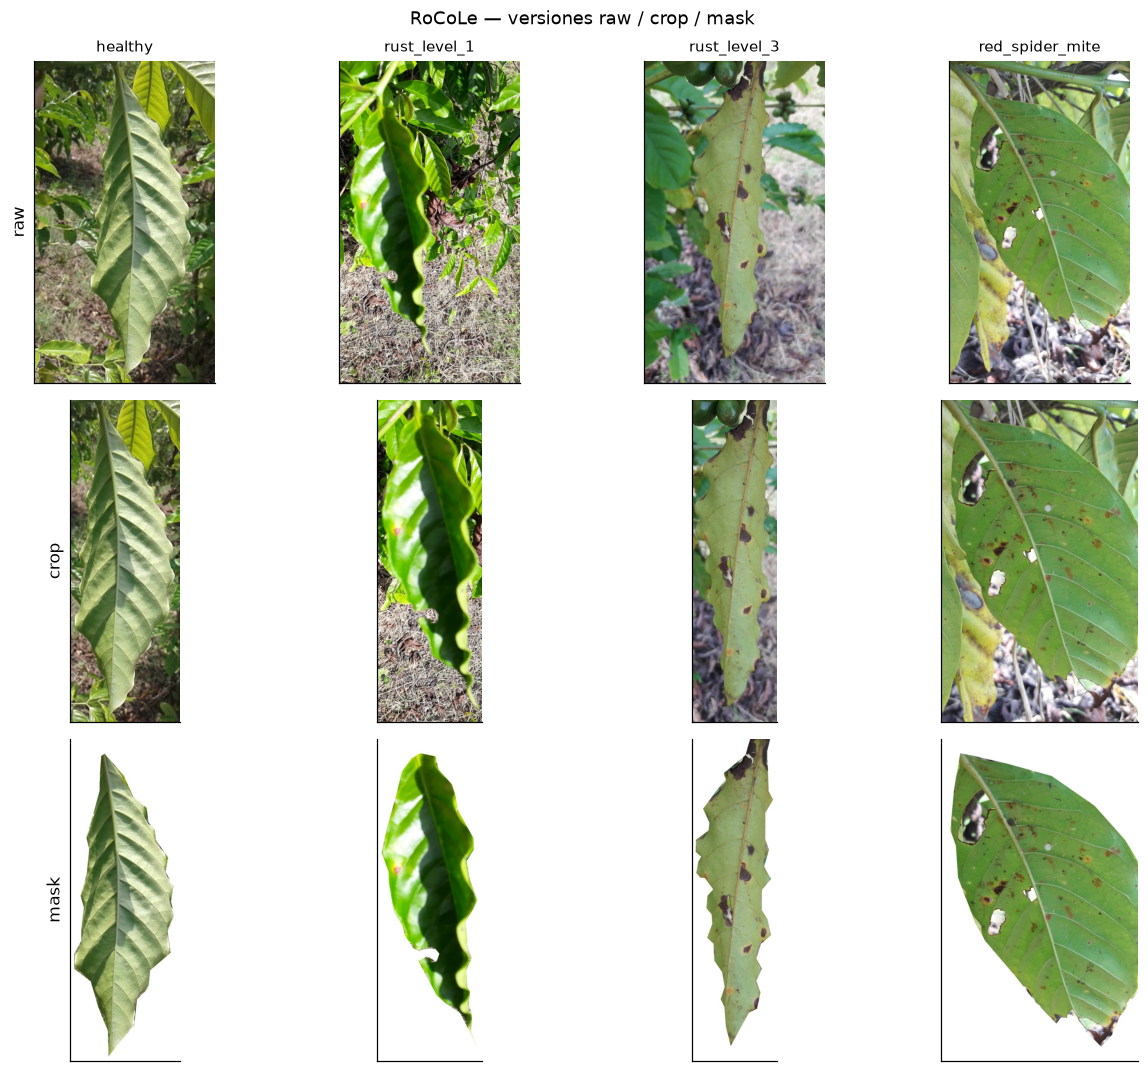

In [9]:
ex_files = (roc.groupby("rocole_class").sample(1, random_state=SEED)
              .set_index("rocole_class").loc[["healthy", "rust_level_1", "rust_level_3", "red_spider_mite"], "file"])
fig, axes = plt.subplots(3, len(ex_files), figsize=(len(ex_files) * 3, 3 * 3.3))
for c, (cls, f) in enumerate(ex_files.items()):
    for r, v in enumerate(("raw", "crop", "mask")):
        ax = axes[r, c]; ax.imshow(Image.open(PROC / "rocole" / v / f)); ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(cls, fontsize=10)
        if c == 0: ax.set_ylabel(v, fontsize=11)
fig.suptitle("RoCoLe — versiones raw / crop / mask")
plt.tight_layout(); plt.savefig(FIG / "01_rocole_versiones.png"); plt.show()

## 5. Cuantificación del cambio de dominio BRACOL → RoCoLe

Se comparan estadísticas simples de bajo nivel (sobre miniaturas de 128 px): brillo, saturación, proporción de píxeles
casi blancos (fondo) y relación de aspecto. Esto **anticipa** los problemas de generalización antes de entrenar.

,brillo,saturacion,frac_blanco,aspecto,R,G,B
dominio,,,,,,,
BRACOL,0.619,0.276,0.295,2.000,0.654,0.655,0.548
RoCoLe-mask,0.710,0.297,0.467,2.742,0.709,0.799,0.622
RoCoLe-raw,0.407,0.445,0.014,1.778,0.414,0.510,0.296


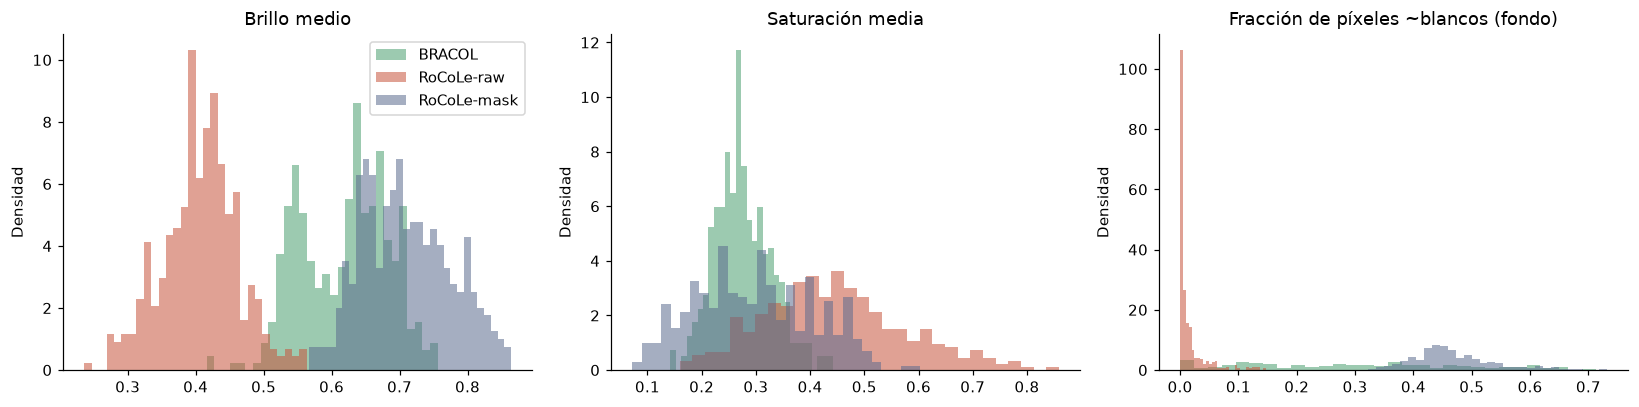

In [10]:
def img_stats(path):
    im = Image.open(path)
    w, h = ImageOps.exif_transpose(im).size
    im = im.convert("RGB"); im.thumbnail((128, 128))
    a = np.asarray(im).astype(np.float32) / 255
    hsv = np.asarray(im.convert("HSV")).astype(np.float32) / 255
    return {"brillo": a.mean(), "saturacion": hsv[..., 1].mean(),
            "frac_blanco": (a.min(axis=2) > 0.8).mean(), "aspecto": max(w, h) / min(w, h),
            "R": a[..., 0].mean(), "G": a[..., 1].mean(), "B": a[..., 2].mean()}

sample_b = bra.sample(400, random_state=SEED)
stats = [dict(img_stats(ROOT / p), dominio="BRACOL") for p in sample_b["path"]]
sample_r = roc.sample(400, random_state=SEED)
for v in ("raw", "mask"):
    stats += [dict(img_stats(PROC / "rocole" / v / f), dominio=f"RoCoLe-{v}") for f in sample_r["file"]]
st = pd.DataFrame(stats)
display(st.groupby("dominio")[["brillo", "saturacion", "frac_blanco", "aspecto", "R", "G", "B"]].mean().round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, ttl in zip(axes, ["brillo", "saturacion", "frac_blanco"],
                        ["Brillo medio", "Saturación media", "Fracción de píxeles ~blancos (fondo)"]):
    for d, c in zip(["BRACOL", "RoCoLe-raw", "RoCoLe-mask"], ["#4C9F70", "#C8553D", "#5B6C8F"]):
        ax.hist(st.loc[st.dominio == d, col], bins=30, alpha=0.55, color=c, label=d, density=True)
    ax.set_title(ttl); ax.set_ylabel("Densidad")
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / "01_cambio_de_dominio.png"); plt.show()

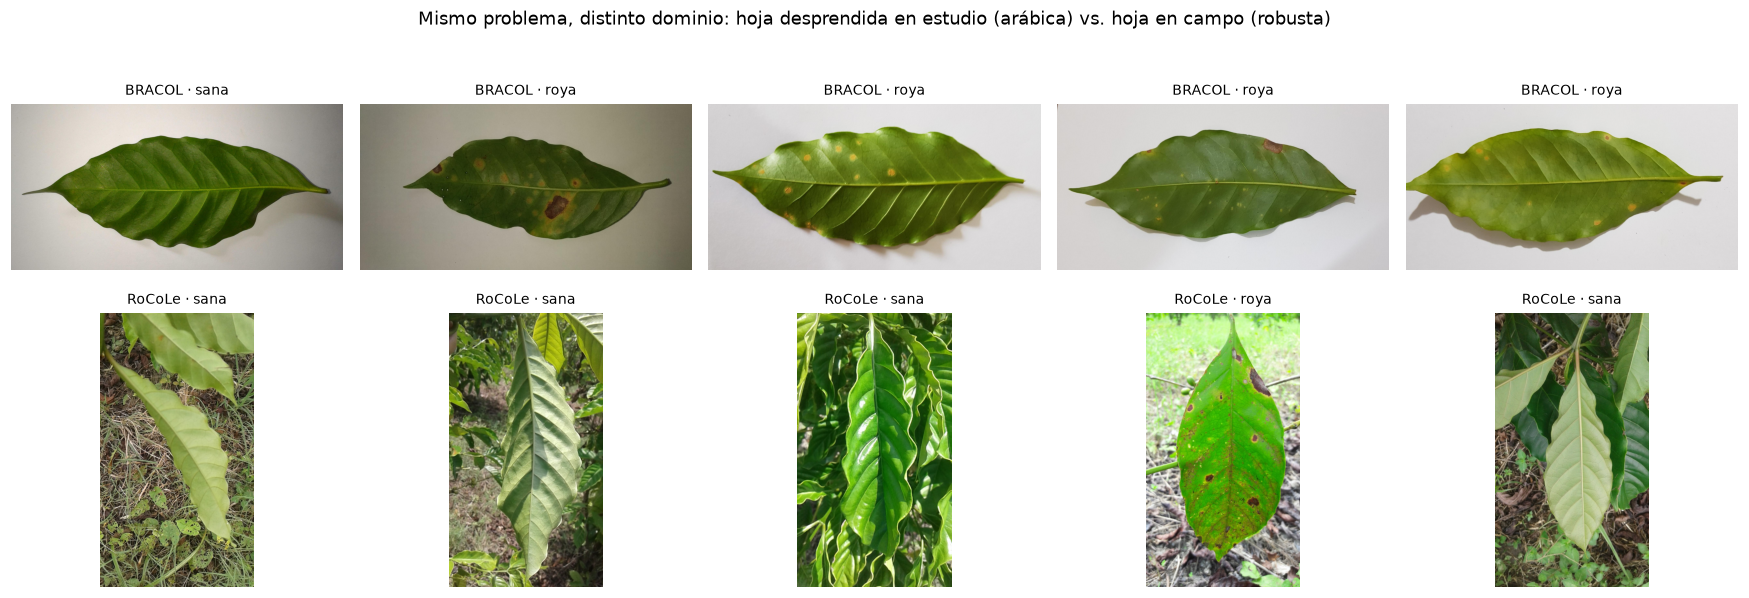

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(16, 5.5))
for ax, (_, r) in zip(axes[0], bra[bra.clase.isin(["sana", "roya"])].sample(5, random_state=1).iterrows()):
    ax.imshow(Image.open(ROOT / r["path"])); ax.set_title(f"BRACOL · {r['clase']}", fontsize=9); ax.axis("off")
for ax, (_, r) in zip(axes[1], roc[roc.label >= 0].sample(5, random_state=1).iterrows()):
    ax.imshow(Image.open(PROC / "rocole" / "raw" / r["file"])); ax.set_title(f"RoCoLe · {r['clase']}", fontsize=9); ax.axis("off")
fig.suptitle("Mismo problema, distinto dominio: hoja desprendida en estudio (arábica) vs. hoja en campo (robusta)")
plt.tight_layout(); plt.savefig(FIG / "01_bracol_vs_rocole.png"); plt.show()

## 6. Resumen para la presentación

| | BRACOL (entrenamiento) | RoCoLe (externo) |
|---|---|---|
| Variedad / país | Arábica · Brasil | Robusta · Ecuador |
| Captura | Hoja desprendida, fondo blanco, horizontal | Hoja en la planta, fondo de campo, vertical (EXIF) |
| Resolución original | 2048×1024 | 1280×720 – 4128×2322 |
| Clases | sana, minador, roya, phoma, cercospora | sana, roya (4 niveles), arañita roja |
| Imágenes usadas | 1685 (70/15/15) | 1393 sana/roya + 167 arañita roja (OOD) |

**Hallazgos clave del EDA** (para discutir en la sustentación):
- Desbalance moderado en BRACOL (cercospora es la clase minoritaria) → pérdida con pesos por clase y métrica **F1-macro**.
- Una fracción importante de hojas tiene **varios estreses simultáneos**; la etiqueta predominante es una simplificación → fuente esperada de confusión.
- El cambio de dominio es fuerte y medible (fondo blanco vs. campo, brillo, aspecto); se espera degradación en RoCoLe-raw y
  recuperación parcial con `crop`/`mask`.

**Siguiente notebook:** `02_entrenamiento.ipynb` — CNN desde cero (baseline), EfficientNet-B0 (transfer learning) y ViT.